# Feature Selection — Breast Cancer Wisconsin (Diagnostic)

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Part of:** the Breast Cancer Wisconsin (Diagnostic) final report, split into
per-step notebooks. See `README.md` for the overall narrative and conclusion.

**Question addressed here:** which features are the most redundant, and which carry the most discriminative signal?

Reduces the 30 raw features down to a small, non-redundant subset that still predicts the diagnosis well, reused unchanged by the two zoom notebooks.

## Setup

Defines the paths used below, imports the reusable functions kept in
`01_scripts/`, and loads the data.

In [7]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.join("..", "01_scripts"))
from dataset import load_data, get_feature_columns
from preprocessing import split_and_scale
from preprocessing import remove_collinear_features
from supervised_models import benchmark_feature_selectors
from plots import plot_feature_selection_plateau

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

df = load_data(DATA_PATH)
features = get_feature_columns(df)

In [2]:
# Same split as the initial screening: 70/30, not 80/20, since malignant is the
# minority class (~37%) and a smaller test set would leave too few malignant
# cases to estimate recall reliably.
X_train_all, X_test_all, y_train, y_test, scaler_all = split_and_scale(
    df, features, test_size=0.3, random_state=RANDOM_STATE
)

## Feature Selection

The correlation heatmap in the exploratory analysis showed strong collinearity between
many features (Pearson |r| > 0.95): several of the 30 features carry almost the same
information. This notebook reduces the 30 features down to a small, non-redundant
subset that still predicts the diagnosis well, in four steps:
- **Removing redundant features**: the most collinear features are dropped first,
  based on the correlation heatmap threshold, using the training set only.
- **Comparing selection methods**: filter methods (score each feature alone) and
  embedded methods (let a model decide) are benchmarked against each other, and
  ranked mainly on recall, F1 and F2.
- **Choosing how many features to keep**: the winning method's regularization
  strength is swept over a range, and the smallest feature count that still keeps
  recall high is kept.
- **Reused downstream**: the final subset is exported and reused, unchanged, by both
  zoom notebooks that follow.

### Removing redundant features

Highly collinear features are removed first, using the training set only.

In [8]:
from sklearn.feature_selection import VarianceThreshold, SelectFdr, f_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate, cross_val_score
from sklearn.metrics import (
    make_scorer, fbeta_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

CV_FOLDS = 10
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f2": make_scorer(fbeta_score, beta=2),
    "roc_auc": "roc_auc",
}

# Remove collinear features (|r| > 0.95), train set only.
df_train_all = pd.DataFrame(X_train_all, columns=features)
df_test_all = pd.DataFrame(X_test_all, columns=features)

features_clean, collinear_features = remove_collinear_features(df_train_all, features, threshold=0.95)

X_train_clean = df_train_all[features_clean].values
X_test_clean = df_test_all[features_clean].values

print(f"Collinear features removed (>0.95): {len(collinear_features)}")
print(f"Remaining features before selection: {len(features_clean)}\n")

Collinear features removed (>0.95): 7
Remaining features before selection: 23


**Findings.** 7 features are removed for being highly collinear (|r| > 0.95) with
another feature already kept, leaving 23 candidate features for the next step.

### Comparing selection methods

Two families of methods are compared:
- **Filter methods** score each feature on its own, independent of any model. Variance
  Threshold removes features with almost no variation across samples. ANOVA F-value
  (via `SelectFdr`) keeps features whose mean differs significantly between benign and
  malignant.
- **Embedded methods** let a model decide which features matter while it is being
  trained. L1-penalized Logistic Regression, L1-penalized LinearSVC, and Elastic-Net
  all use an L1 penalty, which pushes the coefficients of unhelpful features to
  exactly zero, effectively removing them.

Each resulting subset is evaluated with a baseline Logistic Regression, using the same
10-fold cross-validation and the same 6 metrics as the earlier screening. Methods are
ranked mainly on recall, F1 and F2, for the same clinical reason explained earlier:
missing a malignant case matters more than a false alarm.

In [9]:
# Benchmark selection methods (filter + embedded), 10-fold CV, 6 metrics.
selectors = {
    "Variance Threshold (0.01)": VarianceThreshold(threshold=0.01).fit(X_train_clean),
    "SelectFdr (alpha=0.05)": SelectFdr(f_classif, alpha=0.05).fit(X_train_clean, y_train),
    "LogReg L1 (C=0.1)": SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
    "LinearSVC L1 (C=0.05)": SelectFromModel(
        LinearSVC(penalty='l1', dual=False, C=0.05, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
    "Elastic-Net (l1_ratio=0.7)": SelectFromModel(
        LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.7,
                            C=0.1, max_iter=5000, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
}

df_benchmark = benchmark_feature_selectors(
    selectors_dict=selectors, 
    X_train=X_train_clean, 
    y_train=y_train, 
    cv_folds=CV_FOLDS, 
    scoring_dict=SCORING, 
    random_state=RANDOM_STATE
).reset_index()

df_benchmark.to_csv(os.path.join(RESULTS_DIR, "04_feature_selection_benchmark.csv"), index=False)

print(f"--- Feature selection benchmark ({CV_FOLDS}-fold CV, ranked on recall/F1/F2) ---")
display(df_benchmark.round(4))

D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ra

--- Feature selection benchmark (10-fold CV, ranked on recall/F1/F2) ---


,index,model,n_features,accuracy_mean,precision_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean,avg_rank_score
0,2,LogReg L1 (C=0.1),7,0.9646,0.9614,0.9448,0.9520,0.9474,0.9927,2.000
1,1,SelectFdr (alpha=0.05),18,0.9697,0.9805,0.9381,0.9577,0.9456,0.9930,2.375
2,3,LinearSVC L1 (C=0.05),9,0.9671,0.9724,0.9381,0.9543,0.9444,0.9917,2.875
3,4,Elastic-Net (l1_ratio=0.7),6,0.9621,0.9586,0.9376,0.9470,0.9412,0.9918,3.750
4,0,Variance Threshold (0.01),23,0.9697,0.9861,0.9314,0.9570,0.9413,0.9900,4.000


**Findings.** LogReg L1 (C=0.1) ranks best overall: it reaches a strong recall
(0.945) and F2 (0.947) with only 7 features, the fewest of all 5 methods tested.
SelectFdr and Variance Threshold reach similar or slightly higher recall, but only
by keeping 18 to 23 features, more than twice as many for little clinical benefit.
This is why the L1-penalized method is carried forward to the next step.

### Choosing how many features to keep

The embedded method with an L1 penalty (LogReg L1) has one more property: its strength
(`C`) directly controls how many features survive. A range of `C` values is tried, and
recall is tracked against the number of features kept. The smallest feature count that
still reaches close to the best recall is kept, since adding more features beyond that
point does not meaningfully help.

This `C` is different from the one tuned in the Zoom — Logistic Regression notebook:
here it controls how many features are kept; there it regularizes the final model once
the features are already fixed.

D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\Projets (UM5BM753)\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ra

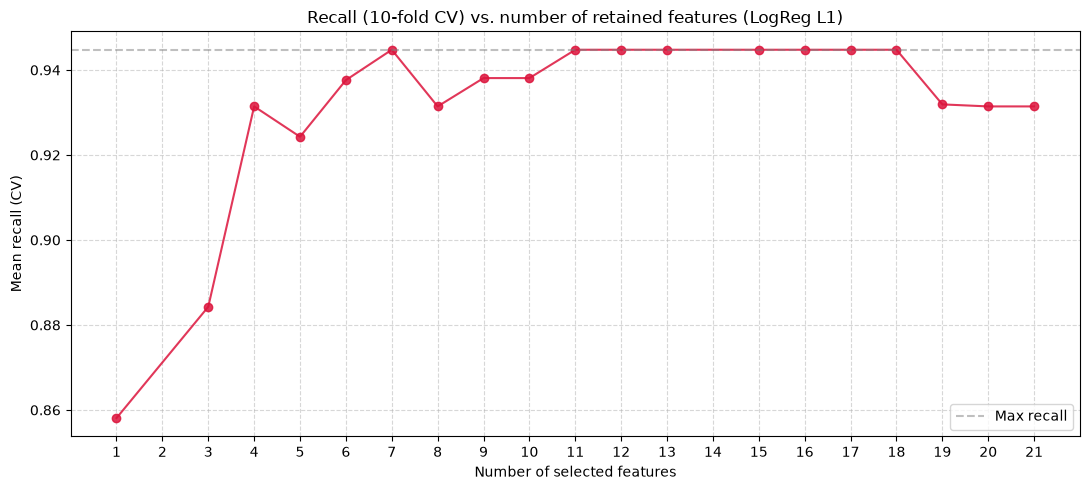

Selected C (feature selection): 0.0624
Number of retained features (plateau): 7
Associated recall (CV): 0.9448
Selected features: ['radius_mean', 'concave_points_mean', 'radius_se', 'texture_worst', 'smoothness_worst', 'concave_points_worst', 'symmetry_worst']


In [10]:
# Tune C for the retained embedded method (LogReg L1): find the feature-count plateau.
C_values = np.logspace(-3, 2, 40)
plateau_results = {}

for C_val in C_values:
    sel = SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=C_val, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train)
    mask = sel.get_support()
    n_feat = int(mask.sum())
    if n_feat == 0:
        continue
    recall_cv = cross_val_score(
        LogisticRegression(random_state=RANDOM_STATE), X_train_clean[:, mask], y_train,
        cv=CV_FOLDS, scoring='recall'
    ).mean()
    if n_feat not in plateau_results or recall_cv > plateau_results[n_feat][0]:
        plateau_results[n_feat] = (recall_cv, C_val, mask)

sorted_n = sorted(plateau_results.keys())
sorted_recall = [plateau_results[n][0] for n in sorted_n]

plot_feature_selection_plateau(
    sorted_n=sorted_n, 
    sorted_recall=sorted_recall, 
    cv_folds=CV_FOLDS, 
    out_path=os.path.join(FIGURES_DIR, "04_feature_selection_plateau.png")
)

# Plateau = smallest feature count whose recall is within a fixed absolute tolerance
# of the observed maximum (tighter and more interpretable than a relative threshold).
RECALL_TOLERANCE = 0.001
recall_max = max(sorted_recall)
n_selected = min(n for n in sorted_n if plateau_results[n][0] >= recall_max - RECALL_TOLERANCE)
best_recall, best_C_selection, best_mask = plateau_results[n_selected]

selected_features = np.array(features_clean)[best_mask].tolist()

print(f"Selected C (feature selection): {best_C_selection:.4f}")
print(f"Number of retained features (plateau): {n_selected}")
print(f"Associated recall (CV): {best_recall:.4f}")
print(f"Selected features: {selected_features}\n")

**Findings.** The plateau is reached at 7 features (C = 0.0624), with a
cross-validated recall of 0.945: adding more features beyond this point does not
meaningfully raise recall further. The 7 retained features are `radius_mean`,
`concave_points_mean`, `radius_se`, `texture_worst`, `smoothness_worst`,
`concave_points_worst`, and `symmetry_worst`.

### Reused downstream

The selected features are exported below, together with a baseline evaluation on the
held-out test set. Two separate files are saved, not one: the train and test sets
must stay apart, matching the split made earlier. Mixing them at this stage would
leak test information into the notebooks that reuse this data.

The two zoom notebooks that follow reuse this exact subset: the supervised model is
retrained on it, and the clustering method is restricted to it. This lets us check
whether the features the supervised model considers important also form natural
groups on their own, without ever using the labels.

In [11]:
# Export restricted datasets, reused unchanged in the two zoom notebooks that follow.
X_train_sel = X_train_clean[:, best_mask]
X_test_sel = X_test_clean[:, best_mask]

pd.DataFrame({"feature": selected_features}).to_csv(os.path.join(RESULTS_DIR, "04_selected_features.csv"), index=False)

PROCESSED_DATA_DIR = os.path.join("..", "02_data", "processed")
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

pd.DataFrame(X_train_sel, columns=selected_features).assign(label=y_train).to_csv(os.path.join(PROCESSED_DATA_DIR, "04_train_selected_features.csv"), index=False)
pd.DataFrame(X_test_sel, columns=selected_features).assign(label=y_test).to_csv(os.path.join(PROCESSED_DATA_DIR, "04_test_selected_features.csv"), index=False)

# Baseline evaluation on the final subset
model_ref = LogisticRegression(random_state=RANDOM_STATE)
model_ref.fit(X_train_sel, y_train)
y_pred = model_ref.predict(X_test_sel)
y_prob = model_ref.predict_proba(X_test_sel)[:, 1]

metrics_final = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "f2": fbeta_score(y_test, y_pred, beta=2),
    "roc_auc": roc_auc_score(y_test, y_prob),
}
df_metrics_final = pd.DataFrame([metrics_final], index=["LogReg (baseline, selected features)"])
df_metrics_final.to_csv(os.path.join(RESULTS_DIR, "04_feature_selection_final_metrics.csv"))

print("--- Final selected subset evaluation (test set, baseline model) ---")
display(df_metrics_final.round(4))

--- Final selected subset evaluation (test set, baseline model) ---


,accuracy,precision,recall,f1,f2,roc_auc
"LogReg (baseline, selected features)",0.9825,0.9841,0.9688,0.9764,0.9718,0.9963


**Findings.** On the held-out test set, this baseline model (default C, not yet
tuned) reaches 0.969 recall and 0.984 precision, close to the cross-validated
estimate from the previous step. This confirms the 7 selected features carry
enough signal on their own, before any further tuning in the next notebooks.

## Discussion

The 7 selected features (`radius_mean`, `concave_points_mean`, `radius_se`,
`texture_worst`, `smoothness_worst`, `concave_points_worst`, `symmetry_worst`)
describe nuclear size, contour irregularity, and symmetry, criteria close to what
pathologists already use visually. They are exported here and reused, unchanged, by
`05_Zoom_LogReg.ipynb` and `06_Zoom_Spectral_Clustering.ipynb`.